In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, ConcatDataset, random_split

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Hyperparameters
BATCH_SIZE = 128
LEARNING_RATE = 0.0002
EPOCHS = 50

# GAN configuration
LATENT_DIM = 100

print("Device:", device)
print("Latent Dimension:", LATENT_DIM)

Device: cuda
Latent Dimension: 100


In [2]:
class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super(Generator, self).__init__()

        self.model = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),

            nn.Linear(256, 512),
            nn.ReLU(),

            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        generated = self.model(z)
        return generated.view(-1, 1, 28, 28)

In [3]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()

        self.model = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 1)
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.model(x)

In [4]:
generator = Generator(
    latent_dim=LATENT_DIM
).to(device)

discriminator = Discriminator().to(device)

print("GENERATOR")
print(generator)

print("\nDISCRIMINATOR")
print(discriminator)

GENERATOR
Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

DISCRIMINATOR
Discriminator(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)


In [5]:
criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=(0.5, 0.999)
)

print("Loss function and optimizers initialized!")

Loss function and optimizers initialized!


In [6]:
transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

print("Training Images:", len(train_dataset))
print("Training Batches:", len(train_loader))

Training Images: 60000
Training Batches: 468


In [7]:
def train_gan(generator, discriminator, train_loader, epochs):

    G_losses = []
    D_losses = []

    for epoch in range(epochs):

        generator.train()
        discriminator.train()

        running_G_loss = 0.0
        running_D_loss = 0.0

        for real_images, _ in train_loader:

            real_images = real_images.to(device)
            batch_size = real_images.size(0)

            real_labels = torch.ones(batch_size, 1).to(device)
            fake_labels = torch.zeros(batch_size, 1).to(device)

            # =========================
            # Train Discriminator
            # =========================

            optimizer_D.zero_grad()

            real_output = discriminator(real_images)

            real_loss = criterion(
                real_output, real_labels
            )

            noise = torch.randn(batch_size, LATENT_DIM).to(device)

            fake_images = generator(noise)

            fake_output = discriminator(fake_images.detach())

            fake_loss = criterion(
                fake_output, fake_labels
            )

            d_loss = real_loss + fake_loss

            d_loss.backward()
            optimizer_D.step()

            # =========================
            # Train Generator
            # =========================

            optimizer_G.zero_grad()

            noise = torch.randn(batch_size, LATENT_DIM).to(device)

            generated_images = generator(noise)

            output = discriminator(generated_images)

            g_loss = criterion(
                output, real_labels
            )

            g_loss.backward()
            optimizer_G.step()

            running_G_loss += g_loss.item()
            running_D_loss += d_loss.item()

        avg_G_loss = running_G_loss / len(train_loader)
        avg_D_loss = running_D_loss / len(train_loader)

        G_losses.append(avg_G_loss)
        D_losses.append(avg_D_loss)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Generator Loss: {avg_G_loss:.4f} "
            f"Discriminator Loss: {avg_D_loss:.4f}"
        )

    return G_losses, D_losses

In [8]:
G_losses, D_losses = train_gan(
    generator,
    discriminator,
    train_loader,
    EPOCHS
)

Epoch [1/50] Generator Loss: 2.5945 Discriminator Loss: 0.4932
Epoch [2/50] Generator Loss: 4.1657 Discriminator Loss: 0.3384
Epoch [3/50] Generator Loss: 3.4057 Discriminator Loss: 0.4752
Epoch [4/50] Generator Loss: 2.8123 Discriminator Loss: 0.5268
Epoch [5/50] Generator Loss: 2.3544 Discriminator Loss: 0.5933
Epoch [6/50] Generator Loss: 2.4473 Discriminator Loss: 0.6584
Epoch [7/50] Generator Loss: 2.0737 Discriminator Loss: 0.7074
Epoch [8/50] Generator Loss: 2.0858 Discriminator Loss: 0.7368
Epoch [9/50] Generator Loss: 2.0703 Discriminator Loss: 0.7185
Epoch [10/50] Generator Loss: 2.0597 Discriminator Loss: 0.7640
Epoch [11/50] Generator Loss: 1.9562 Discriminator Loss: 0.7967
Epoch [12/50] Generator Loss: 1.8259 Discriminator Loss: 0.8245
Epoch [13/50] Generator Loss: 1.7346 Discriminator Loss: 0.8685
Epoch [14/50] Generator Loss: 1.5699 Discriminator Loss: 0.9230
Epoch [15/50] Generator Loss: 1.4964 Discriminator Loss: 0.9437
Epoch [16/50] Generator Loss: 1.5005 Discriminato

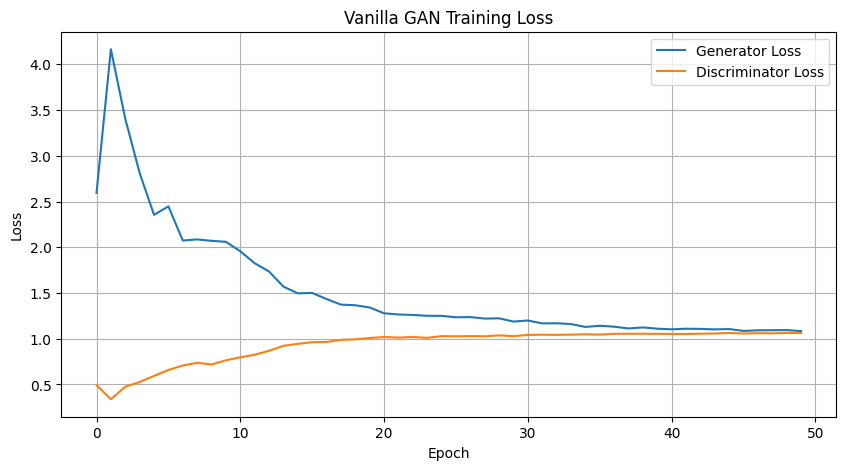

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(G_losses, label="Generator Loss")
plt.plot(D_losses, label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Vanilla GAN Training Loss")

plt.legend()
plt.grid(True)
plt.show()

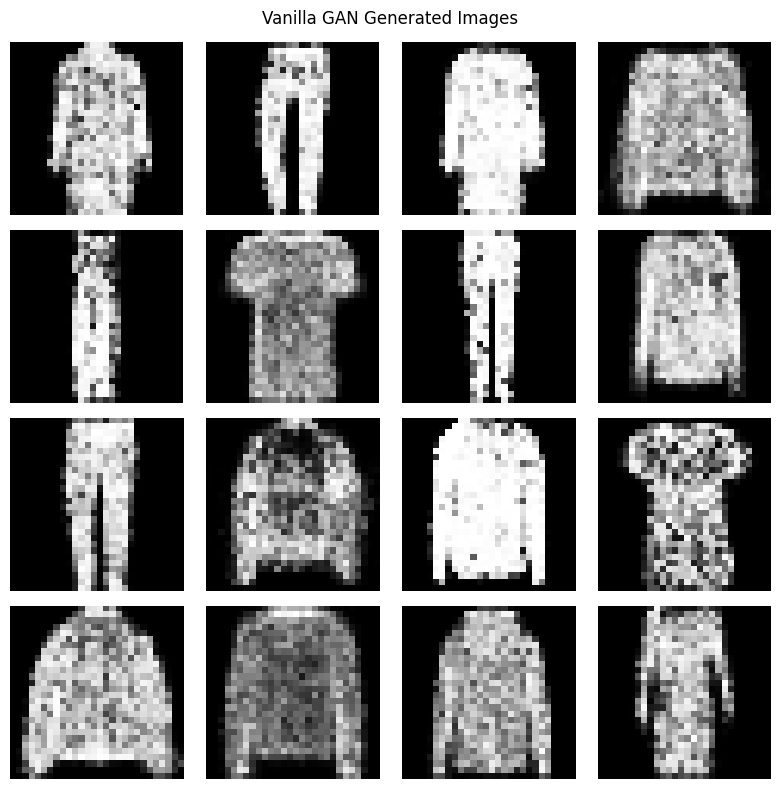

In [11]:
generator.eval()

with torch.no_grad():
    noise = torch.randn(16, LATENT_DIM).to(device)
    generated_images = generator(noise)

generated_images = generated_images.cpu()

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated_images[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("Vanilla GAN Generated Images")
plt.tight_layout()
plt.show()

In [12]:
import os
from torchvision.utils import save_image

os.makedirs("../results/checkpoints", exist_ok=True)
os.makedirs("../results/generated_images", exist_ok=True)

torch.save(
    generator.state_dict(),
    "../results/checkpoints/vanilla_gan_generator.pth"
)

torch.save(
    discriminator.state_dict(),
    "../results/checkpoints/vanilla_gan_discriminator.pth"
)

save_image(
    generated_images,
    "../results/generated_images/vanilla_gan_generated.png",
    nrow=4
)

print("Vanilla GAN results saved!")

Vanilla GAN results saved!
